# 4.3 — Soft-prefix gap across post-training stages

**Pre-registration (written 2026-10-26, before any Experiment 3 run).** Spec: `persona_geom_mixture.md`, Experiment 3.

Question: at which post-training stage does "the base model in some context" stop describing the model?

Checkpoints: OLMo 3 base → Instruct-SFT → Instruct-DPO → Instruct RL revisions step_100, step_200, step_300 → final
Instruct. The RL revisions are the only intermediate revisions on the hub, all in the final RL stage (SFT and DPO
have none). For SFT, DPO and final I reuse the existing 2,400-answer runs (same questions, suffix, default system
message, 80 tokens, T = 1). The step revisions are sampled the same way. The rendered chat-template text is identical for
all checkpoints (checked).

Per checkpoint M_k, on the hold-out half of `data/basis_split.json`:
- self-score: log P_{M_k}(own answer | question), chat template, per token (the −0.898 convention for final Instruct);
- base + soft prefix: prefix trained on the base model to M_k's training-half answers. Main setting L = 128,
  lr = 5e-3, 8 epochs, early stopping on 20% of the training questions (notebook 3.6). Check grid L ∈ {16, 64} ×
  lr ∈ {5e-3, 2e-2}. The reported number is the best by **validation**, never by hold-out;
- optimizer control: the same L = 128 prefix trained on M_k itself; must reach within 0.05 nats/token of the
  self-score, otherwise the base number for that checkpoint is flagged as uninterpretable;
- gap_k = self-score − base + prefix score, with a question bootstrap;
- arithmetic mixture (EM over the 87 base contexts) for every checkpoint. Geometric fit A for SFT, DPO and final if the
  hidden-state storage fits in the budget.

How each outcome will be read (from the spec):

| Result | Reading |
|---|---|
| Gap ≈ 0 at SFT and growing at DPO/RL | Selection describes SFT; later stages change the dynamics |
| Gap already large at SFT | Even supervised post-training goes beyond selection in this setting |

If the error band overlaps the boundary between the two rows, I will say so rather than pick one.

My own prior (for the record): the gap is already large at SFT. Notebook 1.9 found that the distance from the best persona
mixture is 0.65 nats/token at SFT vs 0.82 at final, so most of the change happens at SFT. I expect the soft prefix
to close a similar fraction (roughly 40–50%) at each stage, so gap_SFT is 0.3–0.4 and grows by less than 0.15 through
DPO and RL. Within RL (steps 100–300 → final) I expect little change.


## Setup

Everything below reads saved outputs. The GPU work was done by `scripts/phase4_exp3_stage.sh` (sampling the RL step
revisions, base-model scores of the 87 contexts, per-token self-scores, the five base prefixes and the control prefix per
checkpoint) and `scripts/phase4_exp3_geom.sh` (geometric fit A for SFT and DPO); commands, commits and logs are in
`NOTES.md` (2026-10-27 entries). The analysis below is rerun from the saved per-answer scores. Hold-out = the 150 test
questions of `data/basis_split.json`; ± = question bootstrap (300 resamples, seed 1) of the paired difference to the
self-score.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
REPO = Path.cwd().resolve().parent; os.chdir(REPO)
print(subprocess.run([sys.executable, "scripts/phase4_exp3_analysis.py"], capture_output=True, text=True).stdout)
S = json.load(open("results/phase4/exp3/summary.json"))["checkpoints"]

sft      self -1.2487  generic -1.9285  arithmetic -1.8972  prefix[base_L64_lr5e-3] -1.6597  gap 0.411 ± 0.005  control -0.044 (pass)
dpo      self -1.0367  generic -1.8555  arithmetic -1.8195  prefix[base_L128_lr5e-3] -1.5401  gap 0.503 ± 0.006  control -0.054 (FAIL)
step100  self -1.0303  generic -1.8509  arithmetic -1.8151  prefix[base_L128_lr5e-3] -1.5275  gap 0.497 ± 0.006  control -0.048 (pass)
step200  self -1.0126  generic -1.8263  arithmetic -1.7902  prefix[base_L128_lr5e-3] -1.5012  gap 0.489 ± 0.006  control -0.051 (FAIL)
step300  self -1.0036  generic -1.8109  arithmetic -1.7748  prefix[base_L64_lr5e-3] -1.4854  gap 0.482 ± 0.006  control -0.058 (FAIL)
final    self -0.8985  generic -1.7584  arithmetic -1.7225  prefix[base_L64_lr2e-2] -1.3958  gap 0.497 ± 0.006  control -0.062 (FAIL)
-> results/phase4/exp3/summary.json



## 1. Gap per checkpoint

`gap` = self − base + prefix (the setting chosen on validation). `gap_arith` and `gap_geom` are the same distance for the
arithmetic mixture and geometric fit A of the 87 base contexts. `closed` = share of the arithmetic → self distance the
prefix covers.

In [2]:
rows = []
for k, v in S.items():
    L = v["logp"]; r = {"checkpoint": k, "n": v["n_holdout"], "self": L["self"], "generic": L["generic"], "arithmetic": L["arithmetic"],
                        "prefix (chosen)": L["prefix " + v["prefix_chosen"]], "chosen": v["prefix_chosen"],
                        "gap": v["gap"], "± gap": v["gap_se"], "gap_arith": v["gap_arithmetic"], "gap_geom": v.get("gap_geometric"), "± gap_geom": v.get("gap_geometric_se")}
    r["closed"] = 1 - v["gap"] / v["gap_arithmetic"]; rows.append(r)
display(pd.DataFrame(rows).set_index("checkpoint").round(3))

,n,self,generic,arithmetic,prefix (chosen),chosen,gap,± gap,gap_arith,gap_geom,± gap_geom,closed
checkpoint,,,,,,,,,,,,
sft,1200,-1.249,-1.929,-1.897,-1.660,base_L64_lr5e-3,0.411,0.005,0.648,0.565,0.006,0.366
dpo,1200,-1.037,-1.855,-1.820,-1.540,base_L128_lr5e-3,0.503,0.006,0.783,0.686,0.006,0.357
step100,1200,-1.030,-1.851,-1.815,-1.528,base_L128_lr5e-3,0.497,0.006,0.785,NaN,NaN,0.366
step200,1200,-1.013,-1.826,-1.790,-1.501,base_L128_lr5e-3,0.489,0.006,0.778,NaN,NaN,0.372
step300,1199,-1.004,-1.811,-1.775,-1.485,base_L64_lr5e-3,0.482,0.006,0.771,NaN,NaN,0.375
final,1200,-0.898,-1.758,-1.723,-1.396,base_L64_lr2e-2,0.497,0.006,0.824,0.706,0.008,0.396


## 2. The prefix grid and the optimizer control

Validation log P/token of each prefix setting (the selection criterion), and the control: the L128 prefix trained on the
checkpoint itself minus its self-score. Pre-registered rule: the control must be within 0.05.

In [3]:
display(pd.DataFrame({k: v["prefix_val"] for k, v in S.items()}).T.round(4))
display(pd.DataFrame({k: {"control - self": v["control_minus_self"], "pass (|.| <= 0.05)": v["control_pass"], "control best epoch": v["prefix_best_epoch"].get("ctrl_L128_lr5e-3")} for k, v in S.items()}).T)
for k in ["final", "sft"]:
    r = json.load(open(f"results/phase4/exp3/prefix/{k}_ctrl_L128_lr5e-3/result.json"))
    print(k, "control validation by epoch:", [round(e["val_logp"], 3) for e in r["log"]])

,base_L128_lr5e-3,base_L16_lr5e-3,base_L16_lr2e-2,base_L64_lr5e-3,base_L64_lr2e-2,ctrl_L128_lr5e-3
sft,-1.6423,-1.6451,-1.6489,-1.6422,-1.6474,-1.2880
dpo,-1.5060,-1.5093,-1.5110,-1.5077,-1.5072,-1.0694
step100,-1.4708,-1.4736,-1.4793,-1.4727,-1.4779,-1.0573
step200,-1.4530,-1.4620,-1.4670,-1.4576,-1.4573,-1.0388
step300,-1.4284,-1.4285,-1.4333,-1.4264,-1.4311,-1.0302
final,-1.3460,-1.3589,-1.3661,-1.3490,-1.3444,-0.9389


,control - self,pass (|.| <= 0.05),control best epoch
sft,-0.044339,True,1
dpo,-0.0543,False,1
step100,-0.048057,True,2
step200,-0.050785,False,1
step300,-0.058109,False,1
final,-0.061706,False,2


final control validation by epoch: [-0.945, -0.939, -0.941, -0.953, -0.974, -0.999, -1.052, -1.116]
sft control validation by epoch: [-1.288, -1.29, -1.297, -1.307, -1.325, -1.357, -1.418, -1.485]


## 3. Figure 3

-> results/phase4/fig3_stage_gap.png



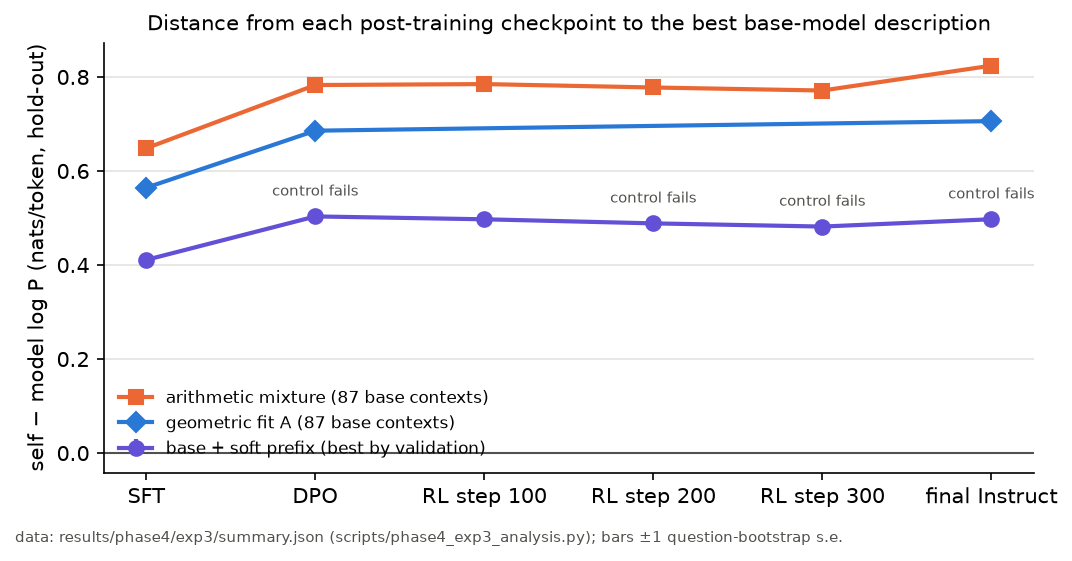

In [4]:
print(subprocess.run([sys.executable, "scripts/phase4_fig3.py"], capture_output=True, text=True).stdout)
display(Image("results/phase4/fig3_stage_gap.png"))

## What we saw (2026-10-27)

**Bottom line: the gap to the base model is already large right after SFT (0.41 nats/token with the soft prefix), grows by
about 0.09 at DPO and then stays flat through RL (0.48–0.50). This is the second pre-registered row: even supervised
post-training goes beyond "the base model in some context" in this setting. Every base-model description (soft prefix,
geometric fit, arithmetic mixture) covers about the same share of the distance at every stage.**

Hold-out log P per token, about 1,200 answers per checkpoint; gaps are self − model, ± question bootstrap of the paired
difference:

| checkpoint | self | gap, soft prefix | gap, geometric fit A | gap, arithmetic mixture |
|---|---|---|---|---|
| SFT | −1.249 | 0.411 ± 0.005 | 0.565 ± 0.006 | 0.649 |
| DPO | −1.037 | 0.503 ± 0.006 | 0.686 ± 0.006 | 0.783 |
| RL step 100 | −1.030 | 0.497 ± 0.006 | – | 0.785 |
| RL step 200 | −1.013 | 0.489 ± 0.006 | – | 0.777 |
| RL step 300 | −1.004 | 0.482 ± 0.006 | – | 0.771 |
| final Instruct | −0.899 | 0.497 ± 0.006 | 0.706 ± 0.008 | 0.824 |

* **Against my prior:** I expected gap_SFT 0.3–0.4 and growth under 0.15; it came in at 0.41 (just above the range) and
  grew by 0.09.
* **Same share at every stage.** Measured from the arithmetic mixture, the soft prefix closes 36–40% of the distance to
  the checkpoint's own score at every stage, and geometric fit A closes 12–14% (SFT 13%, DPO 12%, final 14%). Nothing
  in post-training after SFT makes the model markedly harder or easier to describe, relative to how far it has moved.
* **The geometric fit picks the same contexts at every stage:** hhh, e14, neutral, e60 and fred positive; e34 and e59
  negative, with slightly smaller sizes at SFT (hhh +1.40 at SFT, +1.62 at DPO, +1.70 final).
* **The RL steps (100–300) sit between DPO and final on the self, prefix and arithmetic scores**, and the gap stays within
  0.48–0.50 through RL (step 300 is 0.015 below final, about 2 bootstrap errors). The self-score
  keeps rising (−1.030 → −0.899: the model gets more confident in its own answers) and the best base description keeps
  pace with it.
* **The prefix settings barely matter:** the five settings (L ∈ {16, 64, 128} and two learning rates) differ by less than
  0.022 on validation at each checkpoint; validation picked L128 or L64 every time (learning rate 5e-3 except at the final checkpoint, 2e-2, which beats L128/5e-3 by 0.0016).

**Optimizer control: fails narrowly at 4 of 6 checkpoints, so by the pre-registered rule those base numbers are flagged.**
A prefix trained on the checkpoint itself lands 0.044 (SFT), 0.054 (DPO), 0.048 (step 100), 0.051 (step 200), 0.058
(step 300) and 0.062 (final) below the self-score; the rule was "within 0.05". Two things limit the control: it overfits
after epoch 1–2 (960 training answers, 128 × 4,096 parameters), and its target is partly out of reach by design (the
prefix lives in the transcript format, the self-score uses the chat template). What it bounds: the prefix optimizer leaves
at most about 0.04–0.06 nats/token unreached. If the base prefix were short by the same amount, every gap would still be
at least 0.35 and the shape across stages would not change. I did not re-tune the control to make it pass; in hindsight
the 0.05 threshold was tighter than this control can meet, which is a design problem with the control rather than evidence
that the gaps are small.

**Caveats.** One question split and one seed per prefix; each checkpoint is scored on its own answers, so the checkpoints'
gaps are measured on different answer sets. Only three RL revisions exist on the hub, all early in the RL stage. No
geometric fits for the RL steps (they cost about 1.5 GPU-hours and 100 GB of hidden states each, and the other numbers put
them between DPO and final).
